# Results — `repeat_sampling_rerun_m0fix`

Run `recompute_bf_from_archive.ipynb` first so that `leak_results/bf_results/` and
`no_leak_results/bf_results/` contain CSVs with the Bayes factor column.

## About the log scale (Kass & Raftery 1995, JASA 90:773-795, p.777)

The stored `log_BF_noise` is the **natural logarithm**, ln(B10) — both `gaussian_kde.logpdf`
and `logsumexp` return base-e values. Kass & Raftery report evidence strength on two different
scales, so this notebook plots **both**:

| Scale | Conversion | Grade boundaries | Source |
|---|---|---|---|
| `2 logₑ(B10)` | `2 * log_BF_noise` | 2 / 6 / 10 | Kass & Raftery's own scale (same units as the deviance / LRT statistic) |
| `log₁₀(B10)` | `log_BF_noise / ln(10)` | 0.5 / 1 / 2 | Jeffreys (1961) original |

All three scales (ln, 2ln, log10) are monotone transforms of one another, so the
**ROC curve, the AUC and the ranking of samples are identical** on all of them. What changes is
(a) the axis units and (b) which grade name a given Bayes factor receives. In particular the
threshold for "strong evidence" differs: **Jeffreys BF>10, Kass & Raftery BF>20**.

Figures produced:

1. log(B10) per round — **two panels, 2logₑ and log₁₀** — with evidence-grade bands (leak group)
2. Per-round evidence summary table (three scales + both grading systems)
3. Detection rate per round — **four thresholds compared** (BF>3/10/20/100) + false-positive rate
4. ROC (leak vs no-leak) with the operating point of each threshold
5. M1 relative estimation error per round (leak area / roughness / demand)
6. M0 (no-leak model) estimates vs M1 — diagnostic for the independent M0 update
7. ESS (M1/M0) per round — check for PMC collapse

**You can re-run this at any time before all samples are finished** — it simply uses whatever
samples have completed so far.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from matplotlib.lines import Line2D
from pathlib import Path
from sklearn.metrics import roc_curve, roc_auc_score

LEAK_DIR   = Path('../data/fig_9/leak_results')
NOLEAK_DIR = Path('../data/fig_9/no_leak_results')
CONFIG_COLS = ['i_H1', 'i_H2', 'i_Q1', 'i_Q2', 'leak_loc', 'seed']
ACTUAL = {'leak': 5e-5, 'rough': 1.2, 'demand': 0.75}

# ===== Log-scale definitions (Kass & Raftery 1995, p.777) =====
LN10 = np.log(10)

# The stored log_BF_noise is ln(B10); convert to the two reporting scales here.
SCALES = {
    '2ln': dict(
        name='2 log$_e$(B$_{10}$)',
        conv=lambda ln_bf: 2.0 * ln_bf,
        # (lower, upper, grade name) -- Kass & Raftery table, p.777
        bands=[(0.0, 2.0,  'Not worth more\nthan a bare mention'),
               (2.0, 6.0,  'Positive'),
               (6.0, 10.0, 'Strong'),
               (10.0, np.inf, 'Very strong')],
        source='Kass & Raftery (1995)',
    ),
    'log10': dict(
        name='log$_{10}$(B$_{10}$)',
        conv=lambda ln_bf: ln_bf / LN10,
        # (lower, upper, grade name) -- Jeffreys (1961) app. B, reproduced in K&R p.777
        bands=[(0.0, 0.5, 'Borderline'),
               (0.5, 1.0, 'Positive'),
               (1.0, 2.0, 'Strong'),
               (2.0, np.inf, 'Decisive')],
        source='Jeffreys (1961)',
    ),
}

# Detection thresholds are defined on the Bayes factor itself, so they mean the same
# event regardless of the log base:
#   BF>3   : start of 'Positive'  (Kass & Raftery)
#   BF>10  : start of 'Strong'    (Jeffreys)   <- what the stored detected_BF_noise uses
#   BF>20  : start of 'Strong'    (Kass & Raftery)
#   BF>100 : start of 'Decisive'  (Jeffreys)
THRESHOLDS = [
    (3.0,   'BF>3 (K&R Positive)',        'tab:green',  ':'),
    (10.0,  'BF>10 (Jeffreys Strong)',    'tab:blue',   '-'),
    (20.0,  'BF>20 (K&R Strong)',         'tab:orange', '--'),
    (100.0, 'BF>100 (Jeffreys Decisive)', 'tab:red',    '-.'),
]


def evidence_label(ln_bf, scale_key):
    """Map a single ln(B10) value to the grade name used by the given scale."""
    if not np.isfinite(ln_bf):
        return '-'
    sc = SCALES[scale_key]
    v = sc['conv'](ln_bf)
    if v < 0:
        return 'favors H0 (no leak)'
    for lo, hi, nm in sc['bands']:
        if lo <= v < hi:
            return nm.replace('\n', ' ')
    return sc['bands'][-1][2]


print('log_BF_noise is the natural logarithm, ln(B10).')
print(f'  ln(10)  = {LN10:.4f}   <- threshold used by the stored detected_BF_noise (BF10 > 10)')
print(f'  2ln(10) = {2*LN10:.4f}  <- same threshold on the K&R scale (inside "Positive", 2-6)')
print(f'  2ln(20) = {2*np.log(20):.4f}  <- start of "Strong" on the K&R scale')

log_BF_noise is the natural logarithm, ln(B10).
  ln(10)  = 2.3026   <- threshold used by the stored detected_BF_noise (BF10 > 10)
  2ln(10) = 4.6052  <- same threshold on the K&R scale (inside "Positive", 2-6)
  2ln(20) = 5.9915  <- start of "Strong" on the K&R scale


## 2. Load results — duplicate removal, **leak/no-leak pairing**, and sample-count control

In `sampling_results.csv`, leak sample *i* and no-leak sample *i* share exactly the same
`(i_H1, i_H2, i_Q1, i_Q2, leak_loc, seed)`. In other words, no-leak sample *i* is the
**matched control** for leak sample *i*, not an independently drawn case.

Three switches control which samples are used:

| Switch | Meaning |
|---|---|
| `PAIRED` | `True`: keep only sample IDs that have finished in **both** groups, so the two groups always have the same *n* and the comparison stays matched. `False`: use everything that has finished (the two *n* may differ). |
| `N_SAMPLES` | `None`: use every available sample. An integer *k*: use the **first *k*** sample IDs. |
| `SAMPLE_IDS` | An explicit list such as `[0, 1, 2, 5]`. Overrides `N_SAMPLES` when set. |

When the group that is lagging finishes another sample, just re-run this notebook and *n*
grows automatically.

In [2]:
# ===== sample selection =====
PAIRED     = True    # keep only sample IDs finished in BOTH groups (matched design)
N_SAMPLES  = None    # None = use all available; e.g. 10 = use the first 10 sample IDs
SAMPLE_IDS = None    # e.g. [0, 1, 2, 5] to pick explicitly; overrides N_SAMPLES


def load_group(folder):
    """Load bf_results/parameter_estimates_H2Q2_sample*.csv, dropping any sample whose
    (sensor placement, leak_loc, seed) configuration has already been seen."""
    folder = Path(folder) / 'bf_results'
    if not folder.exists():
        return {}, []
    files = sorted(folder.glob('parameter_estimates_H2Q2_sample*.csv'),
                    key=lambda p: int(re.search(r'sample(\d+)', p.stem).group(1)))

    # The metadata actually lives at <group>/sampling_results.csv. The older path
    # (<group>/../random_sampling/sampling_results.csv) does not exist, which silently
    # disabled duplicate removal, so check both.
    meta = None
    for cand in [folder.parent / 'sampling_results.csv',
                 folder.parent.parent / 'random_sampling' / 'sampling_results.csv']:
        if cand.exists():
            meta = pd.read_csv(cand).set_index('test_sample')
            break

    dfs, seen, dropped = {}, set(), []
    for f in files:
        sid = int(re.search(r'sample(\d+)', f.stem).group(1))
        if meta is not None and sid in meta.index and set(CONFIG_COLS).issubset(meta.columns):
            key = tuple(meta.loc[sid, CONFIG_COLS].tolist())
            if key in seen:
                dropped.append(sid)
                continue
            seen.add(key)
        dfs[sid] = pd.read_csv(f)
    return dfs, dropped


leak_dfs, leak_dropped = load_group(LEAK_DIR)
noleak_dfs, noleak_dropped = load_group(NOLEAK_DIR)

print(f'leak    : {len(leak_dfs)} samples available {sorted(leak_dfs)}'
      f'{", dropped as duplicate config " + str(leak_dropped) if leak_dropped else ""}')
print(f'no-leak : {len(noleak_dfs)} samples available {sorted(noleak_dfs)}'
      f'{", dropped as duplicate config " + str(noleak_dropped) if noleak_dropped else ""}')

# ----- pair the two groups -----
if PAIRED and leak_dfs and noleak_dfs:
    common = sorted(set(leak_dfs) & set(noleak_dfs))
    only_leak   = sorted(set(leak_dfs) - set(common))
    only_noleak = sorted(set(noleak_dfs) - set(common))
    leak_dfs   = {s: leak_dfs[s]   for s in common}
    noleak_dfs = {s: noleak_dfs[s] for s in common}
    print(f'\nPAIRED=True  -> keeping the {len(common)} sample IDs finished in both groups: {common}')
    if only_leak:
        print(f'  excluded, leak only    (no-leak not finished yet): {only_leak}')
    if only_noleak:
        print(f'  excluded, no-leak only (leak not finished yet)   : {only_noleak}')

    # verify that the paired samples really share the same configuration
    try:
        mL = pd.read_csv(LEAK_DIR / 'sampling_results.csv').set_index('test_sample')
        mN = pd.read_csv(NOLEAK_DIR / 'sampling_results.csv').set_index('test_sample')
        bad = [s for s in common
               if mL.loc[s, CONFIG_COLS].tolist() != mN.loc[s, CONFIG_COLS].tolist()]
        print(f'  pair configuration check: '
              f'{"all identical (matched pairs)" if not bad else f"MISMATCH at samples {bad} -- please check"}')
    except Exception as e:
        print(f'  pair configuration check skipped: {e}')
elif not PAIRED:
    print('\nPAIRED=False -> using every finished sample (the two groups may have different n)')

# ----- restrict how many samples to use -----
def _select(dfs):
    if not dfs:
        return dfs
    ids = sorted(dfs)
    if SAMPLE_IDS is not None:
        keep = [s for s in SAMPLE_IDS if s in dfs]
    elif N_SAMPLES is not None:
        keep = ids[:N_SAMPLES]
    else:
        keep = ids
    return {s: dfs[s] for s in keep}

if SAMPLE_IDS is not None or N_SAMPLES is not None:
    n_before = (len(leak_dfs), len(noleak_dfs))
    leak_dfs, noleak_dfs = _select(leak_dfs), _select(noleak_dfs)
    how = f'SAMPLE_IDS={SAMPLE_IDS}' if SAMPLE_IDS is not None else f'N_SAMPLES={N_SAMPLES}'
    print(f'\n{how} -> leak {n_before[0]}->{len(leak_dfs)} {sorted(leak_dfs)}, '
          f'no-leak {n_before[1]}->{len(noleak_dfs)} {sorted(noleak_dfs)}')
    missing = [s for s in (SAMPLE_IDS or []) if s not in leak_dfs and s not in noleak_dfs]
    if missing:
        print(f'  requested but not available: {missing}')

print(f'\n>>> USING  leak n={len(leak_dfs)} {sorted(leak_dfs)}   |   '
      f'no-leak n={len(noleak_dfs)} {sorted(noleak_dfs)}')
if leak_dfs:
    print(f'    rounds per sample (leak)    : {[len(d) for d in leak_dfs.values()]}')
if noleak_dfs:
    print(f'    rounds per sample (no-leak) : {[len(d) for d in noleak_dfs.values()]}')

leak    : 10 samples available [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
no-leak : 11 samples available [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

PAIRED=True  -> keeping the 10 sample IDs finished in both groups: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
  excluded, no-leak only (leak not finished yet)   : [10]
  pair configuration check: all identical (matched pairs)

>>> USING  leak n=10 [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]   |   no-leak n=10 [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
    rounds per sample (leak)    : [10, 10, 10, 10, 10, 10, 10, 10, 10, 10]
    rounds per sample (no-leak) : [10, 10, 10, 10, 10, 10, 10, 10, 10, 10]


In [3]:
def to_matrix(dfs, col):
    if not dfs:
        return np.zeros((0, 0))
    max_r = max(len(d) for d in dfs.values())
    mat = np.full((len(dfs), max_r), np.nan)
    for row, sid in enumerate(sorted(dfs)):
        v = dfs[sid][col].values
        mat[row, :len(v)] = v
    return mat

# The archived values are always ln(B10); conversion happens at plot time via SCALES[...]['conv'].
logBF_leak   = to_matrix(leak_dfs, 'log_BF_noise')
logBF_noleak = to_matrix(noleak_dfs, 'log_BF_noise')
rounds = np.arange(1, logBF_leak.shape[1] + 1) if logBF_leak.size else np.array([])
print('logBF_leak   shape:', logBF_leak.shape, '(units: ln)')
print('logBF_noleak shape:', logBF_noleak.shape, '(units: ln)')

# Confirm the stored detected_BF_noise really is BF>10, i.e. that no log base got mixed up.
if leak_dfs:
    chk = []
    for sid, d in leak_dfs.items():
        if 'detected_BF_noise' in d.columns:
            chk.append(np.array_equal(d['detected_BF_noise'].astype(bool).values,
                                      (d['log_BF_noise'].values > LN10)))
    if chk:
        print(f'check detected_BF_noise == (ln BF > ln 10): '
              f'{"all match" if all(chk) else "MISMATCH -- please check"}')

logBF_leak   shape: (10, 10) (units: ln)
logBF_noleak shape: (10, 10) (units: ln)
check detected_BF_noise == (ln BF > ln 10): all match


## 3. Figure 1 — log(B10) per round on **both log scales** (leak group)

The same `log_BF_noise` (= ln B10) plotted on the Kass & Raftery `2 logₑ` scale (left) and on the
Jeffreys `log₁₀` scale (right). The curves have identical shape because the two differ only by a
constant factor — what changes is **where the evidence-grade bands fall**.
The dashed red line is the no-leak median, which should stay negative (i.e. favouring H0).

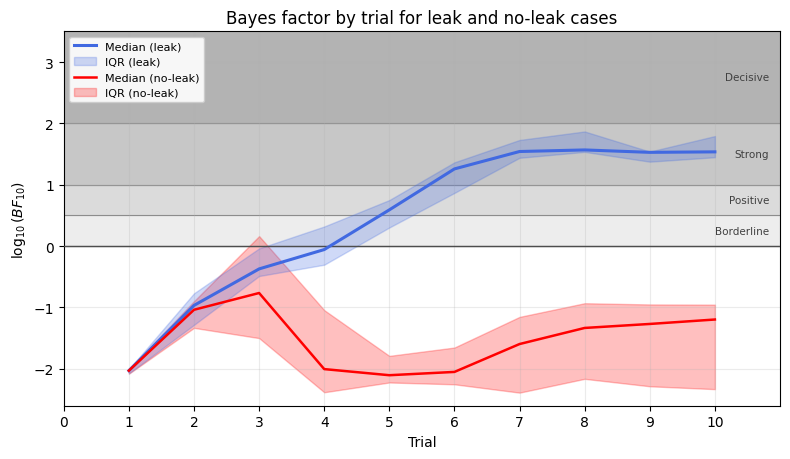

saved: logBF_two_scales.png


In [4]:
if logBF_leak.size:
    fig, ax = plt.subplots(figsize=(8, 5))

    key = 'log10'
    sc = SCALES[key]
    M = sc['conv'](logBF_leak)                  # (n_samples, n_rounds) on the target scale
    med = np.nanmedian(M, axis=0)
    p25, p75 = np.nanpercentile(M, 25, axis=0), np.nanpercentile(M, 75, axis=0)
    p05, p95 = np.nanpercentile(M, 5, axis=0), np.nanpercentile(M, 95, axis=0)

    # fix the y-range first so the bands do not run off the axes
    lo = min(np.nanmin(M), 0.0) - 0.5
    #hi = max(np.nanmax(M), sc['bands'][-1][0] * 1.1) + 0.5
    hi = 3.5

    # --- evidence-grade bands (background) ---
    band_colors = ['0.93', '0.86', '0.78', '0.70']
    for (b_lo, b_hi, nm), bc in zip(sc['bands'], band_colors):
        top = min(b_hi, hi)
        if top <= b_lo:
            continue
        ax.axhspan(b_lo, top, color=bc, zorder=0)
        ax.axhline(b_lo, color='0.55', linewidth=0.8, linestyle='-', zorder=1)
        ax.text(0.985, (b_lo + top) / 2 if np.isfinite(b_hi) else (b_lo + hi) / 2,
                nm, transform=ax.get_yaxis_transform(), ha='right', va='center',
                fontsize=7.5, color='0.25', zorder=2)

    # --- individual samples, quantile bands, median ---
    #for row in M:
    #    ax.plot(rounds, row, color='steelblue', alpha=0.18, linewidth=0.8, zorder=3)
    #ax.fill_between(rounds, p05, p95, color='steelblue', alpha=0.18, zorder=3, label='[5, 95]%')
    ax.plot(rounds, med, color='royalblue', linewidth=2.2, zorder=5, label='Median (leak)')
    ax.fill_between(rounds, p25, p75, color='royalblue', alpha=0.25, zorder=3, label='IQR (leak)')#, label='[25, 75]%')

    # --- no-leak median for contrast ---
    if logBF_noleak.size:
        n_common = min(len(rounds), logBF_noleak.shape[1])
        M0 = sc['conv'](logBF_noleak)
        med_nl = np.nanmedian(M0, axis=0)[:n_common]
        p25, p75 = np.nanpercentile(M0, 25, axis=0), np.nanpercentile(M0, 75, axis=0)
        ax.plot(rounds[:n_common], med_nl, color='r', linewidth=1.8,
                linestyle='-', zorder=5, label='Median (no-leak)')
        ax.fill_between(rounds, p25, p75, color='r', alpha=0.25, zorder=1, label='IQR (no-leak)')#, label='[25, 75]%')

    # --- detection thresholds ---
    #for bf, lab, col, ls in THRESHOLDS:
    #    if bf not in (10.0, 20.0):
    #        continue
    #    ax.axhline(sc['conv'](np.log(bf)), color=col, linewidth=1.4, linestyle=ls, zorder=4,
    #                label=f'BF={bf:g}  ({sc["conv"](np.log(bf)):.2f})')

    ax.axhline(0, color='0.3', linewidth=1.0, zorder=4)
    ax.set_ylim(lo, hi)
    ax.set_xlim(0, 11)
    ax.set_xlabel('Trial')
    ax.set_ylabel('$\log_{10}(BF_{10})$')
    #ax.set_title(f"{sc['name']}  —  {sc['source']} scale")
    ax.set_title('Bayes factor by trial for leak and no-leak cases')
    #ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.xaxis.set_ticks([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10])
    ax.grid(alpha=0.25, zorder=2)

    ax.legend(loc='upper left', fontsize=8, framealpha=0.9)
    #plt.suptitle('Bayes factor per round on two log scales — '
    #             f'leak n={len(leak_dfs)}, no-leak n={len(noleak_dfs)}', fontsize=12)
    plt.tight_layout(rect=[0, 0, 1, 0.94])
    plt.savefig('logBF_two_scales.png', dpi=150, transparent=True)
    plt.show()
    print('saved: logBF_two_scales.png')
else:
    print('no finished leak samples yet -- run the simulation notebook first')

## 3-b. Per-round evidence summary table (three scales, two grading systems)

The round-wise median of `log_BF_noise` (ln) shown on all three scales, with the grade name it
receives under Kass & Raftery and under Jeffreys. This is the table to cite when writing something
like "the median reaches Strong evidence at round N". Also written to
`evidence_summary_two_scales.csv`.

In [5]:
if logBF_leak.size:
    med_ln = np.nanmedian(logBF_leak, axis=0)
    rows = []
    for r, m in zip(rounds, med_ln):
        row = {
            'round': int(r),
            'n': int(np.sum(~np.isnan(logBF_leak[:, r - 1]))),
            'ln_BF (stored)': round(float(m), 3),
            '2ln_BF (K&R)': round(float(2 * m), 3),
            'log10_BF (Jeffreys)': round(float(m / LN10), 3),
            'BF10': round(float(np.exp(m)), 2),
            'K&R grade': evidence_label(m, '2ln'),
            'Jeffreys grade': evidence_label(m, 'log10'),
        }
        for bf, lab, _, _ in THRESHOLDS:
            col = logBF_leak[:, r - 1]
            row[f'TPR@BF>{bf:g}'] = round(100 * float(np.nanmean(col > np.log(bf))), 1)
        if logBF_noleak.size and r <= logBF_noleak.shape[1]:
            coln = logBF_noleak[:, r - 1]
            for bf, lab, _, _ in THRESHOLDS:
                row[f'FPR@BF>{bf:g}'] = round(100 * float(np.nanmean(coln > np.log(bf))), 1)
        rows.append(row)

    summary = pd.DataFrame(rows).set_index('round')
    summary.to_csv('evidence_summary_two_scales.csv')

    disp_cols = ['n', 'ln_BF (stored)', '2ln_BF (K&R)', 'log10_BF (Jeffreys)', 'BF10',
                 'K&R grade', 'Jeffreys grade']
    display(summary[disp_cols])

    rate_cols = [c for c in summary.columns if c.startswith(('TPR', 'FPR'))]
    print('\nDetection rate (TPR, leak group) and false-positive rate (FPR, no-leak group), in %')
    display(summary[rate_cols])

    print('\nFirst round at which the median reaches each grade')
    for key in ['2ln', 'log10']:
        sc = SCALES[key]
        for lo, hi, nm in sc['bands'][1:]:
            hit = [int(r) for r, m in zip(rounds, med_ln) if sc['conv'](m) >= lo]
            nm1 = nm.replace('\n', ' ')
            print(f"  [{sc['source']:22s}] {nm1:32s} ({sc['name'].replace('$','')} >= {lo:g}) : "
                  f"{('round ' + str(hit[0])) if hit else 'not reached'}")
    print('\nsaved: evidence_summary_two_scales.csv')
else:
    print('no finished leak samples yet')

,n,ln_BF (stored),2ln_BF (K&R),log10_BF (Jeffreys),BF10,K&R grade,Jeffreys grade
round,,,,,,,
1,10,-4.676,-9.352,-2.031,0.01,favors H0 (no leak),favors H0 (no leak)
2,10,-2.229,-4.458,-0.968,0.11,favors H0 (no leak),favors H0 (no leak)
3,10,-0.858,-1.716,-0.373,0.42,favors H0 (no leak),favors H0 (no leak)
4,10,-0.132,-0.264,-0.057,0.88,favors H0 (no leak),favors H0 (no leak)
5,10,1.358,2.716,0.590,3.89,Positive,Positive
6,10,2.895,5.790,1.257,18.09,Positive,Strong
7,10,3.548,7.097,1.541,34.75,Strong,Strong
8,10,3.608,7.215,1.567,36.88,Strong,Strong
9,10,3.517,7.033,1.527,33.67,Strong,Strong



Detection rate (TPR, leak group) and false-positive rate (FPR, no-leak group), in %


,TPR@BF>3,TPR@BF>10,TPR@BF>20,TPR@BF>100,FPR@BF>3,FPR@BF>10,FPR@BF>20,FPR@BF>100
round,,,,,,,,
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,20.0,0.0,0.0,0.0,10.0,0.0,0.0,0.0
4,10.0,10.0,0.0,0.0,10.0,0.0,0.0,0.0
5,70.0,10.0,0.0,0.0,0.0,0.0,0.0,0.0
6,90.0,60.0,40.0,0.0,0.0,0.0,0.0,0.0
7,100.0,100.0,80.0,0.0,0.0,0.0,0.0,0.0
8,100.0,100.0,80.0,10.0,0.0,0.0,0.0,0.0
9,90.0,90.0,80.0,0.0,0.0,0.0,0.0,0.0



First round at which the median reaches each grade
  [Kass & Raftery (1995) ] Positive                         (2 log_e(B_{10}) >= 2) : round 5
  [Kass & Raftery (1995) ] Strong                           (2 log_e(B_{10}) >= 6) : round 7
  [Kass & Raftery (1995) ] Very strong                      (2 log_e(B_{10}) >= 10) : not reached
  [Jeffreys (1961)       ] Positive                         (log_{10}(B_{10}) >= 0.5) : round 5
  [Jeffreys (1961)       ] Strong                           (log_{10}(B_{10}) >= 1) : round 6
  [Jeffreys (1961)       ] Decisive                         (log_{10}(B_{10}) >= 2) : not reached

saved: evidence_summary_two_scales.csv


## 4. Figure 2 — detection rate per round, **four thresholds compared**

Changing the log base does not change the event "B10 > c", so detection is defined directly on the
Bayes factor:

- `BF>3` — start of 'Positive' (Kass & Raftery)
- `BF>10` — start of 'Strong' (Jeffreys); this is what the stored `detected_BF_noise` uses (`ln BF > 2.303`)
- `BF>20` — start of 'Strong' (Kass & Raftery) (`2ln BF > 6`)
- `BF>100` — start of 'Decisive' (Jeffreys)

Left: detection rate (TPR) in the leak group. Right: false-positive rate (FPR) in the no-leak group.
Both panels are needed to judge how much earlier a lower threshold detects and at what cost.

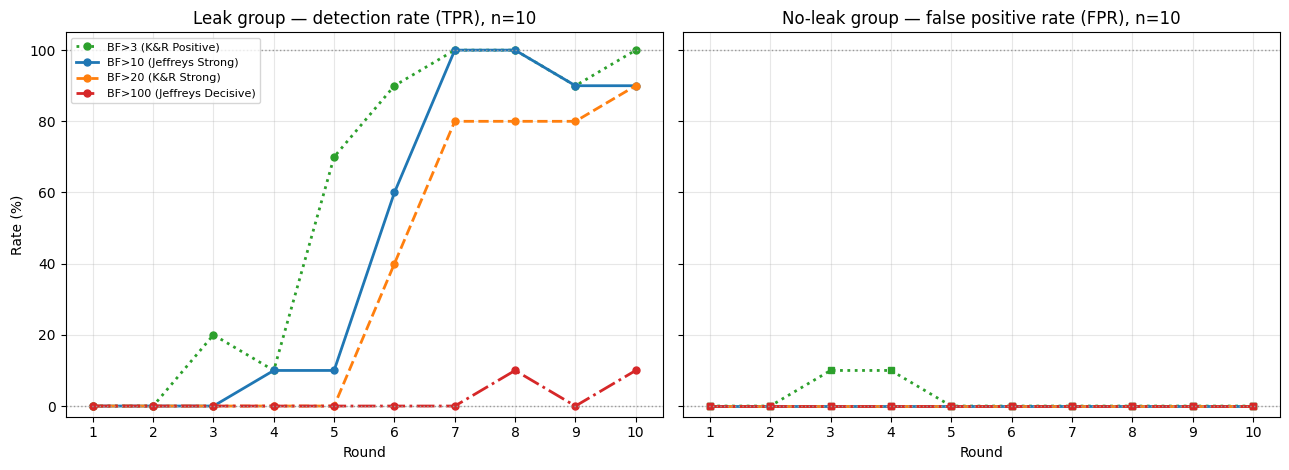

stored detected_BF_noise matches recomputed BF>10: True
saved: detection_rate_thresholds.png


In [6]:
if logBF_leak.size:
    fig, axs = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)

    for bf, lab, col, ls in THRESHOLDS:
        thr_ln = np.log(bf)
        tpr = 100 * np.nanmean(logBF_leak > thr_ln, axis=0)
        axs[0].plot(rounds, tpr, marker='o', color=col, linestyle=ls, linewidth=2,
                    markersize=5, label=lab)
        if logBF_noleak.size:
            n_common = min(len(rounds), logBF_noleak.shape[1])
            fpr = 100 * np.nanmean(logBF_noleak > thr_ln, axis=0)[:n_common]
            axs[1].plot(rounds[:n_common], fpr, marker='s', color=col, linestyle=ls, linewidth=2,
                        markersize=5, label=lab)

    axs[0].set_title(f'Leak group — detection rate (TPR), n={len(leak_dfs)}')
    axs[1].set_title(f'No-leak group — false positive rate (FPR), n={len(noleak_dfs)}')
    for ax in axs:
        ax.axhline(100, linestyle=':', color='0.6', linewidth=1)
        ax.axhline(0, linestyle=':', color='0.6', linewidth=1)
        ax.set_xlabel('Round')
        ax.set_ylim(-3, 105)
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.grid(alpha=0.3)
    axs[0].set_ylabel('Rate (%)')
    axs[0].legend(loc='upper left', fontsize=8)
    plt.tight_layout()
    plt.savefig('detection_rate_thresholds.png', dpi=150, transparent=True)
    plt.show()

    # cross-check against the stored detected_BF_noise column (fixed at BF>10)
    det_mat = np.zeros_like(logBF_leak, dtype=bool)
    for row, sid in enumerate(sorted(leak_dfs)):
        flags = leak_dfs[sid]['detected_BF_noise'].astype(bool).values
        det_mat[row, :len(flags)] = flags
    same = np.array_equal(det_mat, np.nan_to_num(logBF_leak, nan=-np.inf) > LN10)
    print(f'stored detected_BF_noise matches recomputed BF>10: {same}')
    print('saved: detection_rate_thresholds.png')
else:
    print('no finished leak samples yet')

## 5. Figure 3 — ROC (leak vs no-leak) with threshold operating points

**The ROC curve and the AUC are identical on every log scale** — ln, 2ln and log10 are all
monotone increasing transforms, so the ranking of samples never changes. The ROC is therefore
drawn once, and the four thresholds are marked as operating points on the curve.

In [7]:
THRESHOLDS = [(3.0, 'BF>3 (Jeffreys Positive)', 'tab:blue', '--'),
 (10.0, 'BF>10 (Jeffreys Strong)', 'tab:orange', '-'),
 (100.0, 'BF>100 (Jeffreys Decisive)', 'tab:red', '-.')]

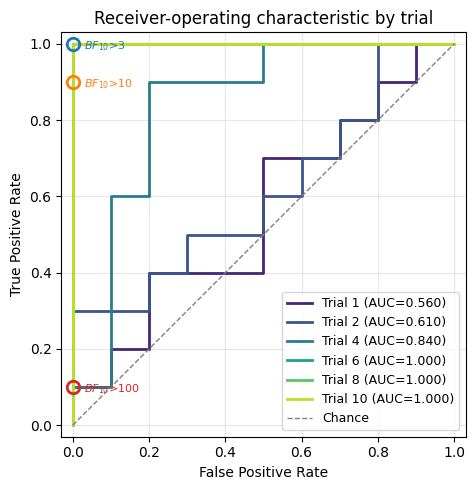

Final-round (10) AUC: 1.000
AUC invariance check -- ln: 1.000000, 2ln: 1.000000, log10: 1.000000


In [8]:
# Rounds to draw on the ROC. Entries beyond the number of finished rounds are dropped.
ROC_ROUNDS = [1, 2, 4, 6, 8, 10]

if logBF_leak.size and logBF_noleak.size:
    n_rounds_common = min(logBF_leak.shape[1], logBF_noleak.shape[1])

    def roc_for_round(r):
        pos = logBF_leak[:, r - 1]
        neg = logBF_noleak[:, r - 1]
        y_score = np.r_[pos, neg]
        y_true = np.r_[np.ones_like(pos), np.zeros_like(neg)]
        mask = ~np.isnan(y_score)
        fpr, tpr, thr = roc_curve(y_true[mask], y_score[mask])
        auc = roc_auc_score(y_true[mask], y_score[mask])
        return fpr, tpr, thr, auc

    rounds_to_plot = sorted({r for r in ROC_ROUNDS if 1 <= r <= n_rounds_common})
    if not rounds_to_plot:
        rounds_to_plot = [n_rounds_common]
    dropped = [r for r in ROC_ROUNDS if r > n_rounds_common]
    if dropped:
        print(f'requested rounds beyond the {n_rounds_common} finished rounds, skipped: {dropped}')
    colors = plt.cm.viridis(np.linspace(0.10, 0.90, len(rounds_to_plot)))

    fig, ax = plt.subplots(figsize=(5, 5))
    for r, c in zip(rounds_to_plot, colors):
        fpr, tpr, _, auc = roc_for_round(r)
        ax.plot(fpr, tpr, color=c, linewidth=2, label=f'Trial {r} (AUC={auc:.3f})')

    # --- operating point of each BF threshold at the final round ---
    r = n_rounds_common
    pos, neg = logBF_leak[:, r - 1], logBF_noleak[:, r - 1]
    for bf, lab, col, ls in THRESHOLDS:
        thr_ln = np.log(bf)
        t = np.nanmean(pos > thr_ln)
        f = np.nanmean(neg > thr_ln)
        ax.plot(f, t, marker='o', markersize=9, markerfacecolor='none',
                markeredgecolor=col, markeredgewidth=2, linestyle='none')
        ax.annotate(f'$BF_{{10}}$>{bf:g}', (f, t), textcoords='offset points', xytext=(8, -4),
                    fontsize=8, color=col)

    ax.plot([0, 1], [0, 1], '--', color='0.5', linewidth=1, label='Chance')
    ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate')
    #ax.set_title(f'ROC — leak (n={len(leak_dfs)}) vs no-leak (n={len(noleak_dfs)})\n'
    #             f'operating points at round {r}  (ROC/AUC invariant to log base)', fontsize=10)
    ax.set_title('Receiver-operating characteristic by trial')
    ax.set_aspect('equal'); ax.set_xlim(-0.03, 1.03); ax.set_ylim(-0.03, 1.03)
    ax.grid(alpha=0.3); ax.legend(loc='lower right', fontsize=9)
    plt.tight_layout()
    plt.savefig('roc_noise.png', dpi=150, transparent=True)
    plt.show()

    _, _, _, auc_final = roc_for_round(n_rounds_common)
    print(f'Final-round ({n_rounds_common}) AUC: {auc_final:.3f}')

    # verify directly that the AUC does not depend on the log base
    y_true = np.r_[np.ones_like(pos), np.zeros_like(neg)]
    s_ln = np.r_[pos, neg]
    mask = ~np.isnan(s_ln)
    auc_ln    = roc_auc_score(y_true[mask], s_ln[mask])
    auc_2ln   = roc_auc_score(y_true[mask], (2 * s_ln)[mask])
    auc_log10 = roc_auc_score(y_true[mask], (s_ln / LN10)[mask])
    print(f'AUC invariance check -- ln: {auc_ln:.6f}, 2ln: {auc_2ln:.6f}, log10: {auc_log10:.6f}')
else:
    print('at least one finished sample is needed in each group to draw the ROC')

In [9]:
THRESHOLDS

[(3.0, 'BF>3 (Jeffreys Positive)', 'tab:blue', '--'),
 (10.0, 'BF>10 (Jeffreys Strong)', 'tab:orange', '-'),
 (100.0, 'BF>100 (Jeffreys Decisive)', 'tab:red', '-.')]

## 6. Figure 4 — M1 relative estimation error per round (leak group)

`estimated_leak_area` / `estimated_roughness` / `estimated_demand`. Independent of the Bayes
factor — this looks only at the point estimates.

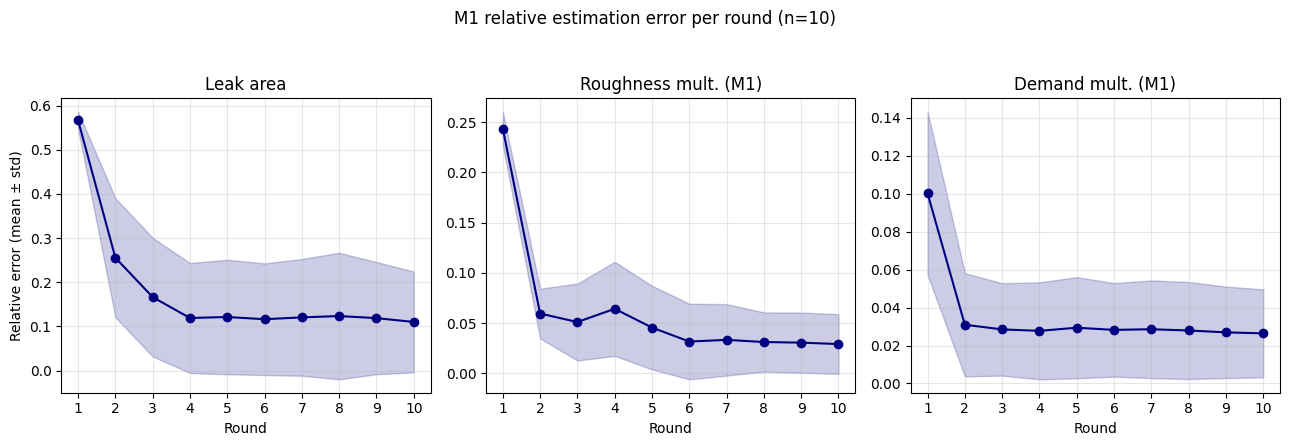

In [10]:
if leak_dfs:
    def rel_err_matrix(dfs, col, truth):
        max_r = max(len(d) for d in dfs.values())
        mat = np.full((len(dfs), max_r), np.nan)
        for row, sid in enumerate(sorted(dfs)):
            v = dfs[sid][col].values
            mat[row, :len(v)] = np.abs(v - truth) / truth
        return mat

    err_leak = rel_err_matrix(leak_dfs, 'estimated_leak_area', ACTUAL['leak'])
    err_rough = rel_err_matrix(leak_dfs, 'estimated_roughness', ACTUAL['rough'])
    err_demand = rel_err_matrix(leak_dfs, 'estimated_demand', ACTUAL['demand'])

    fig, axs = plt.subplots(1, 3, figsize=(13, 4.5), sharex=True)
    for ax, err, name in zip(axs, [err_leak, err_rough, err_demand],
                              ['Leak area', 'Roughness mult. (M1)', 'Demand mult. (M1)']):
        m = np.nanmean(err, axis=0)
        s = np.nanstd(err, axis=0)
        ax.plot(rounds, m, 'o-', color='navy')
        ax.fill_between(rounds, m - s, m + s, color='navy', alpha=0.2)
        ax.set_title(name)
        ax.set_xlabel('Round')
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.grid(alpha=0.3)
    axs[0].set_ylabel('Relative error (mean ± std)')
    plt.suptitle(f'M1 relative estimation error per round (n={len(leak_dfs)})')
    plt.tight_layout(rect=[0, 0, 1, 0.94])
    plt.savefig('m1_relative_error.png', dpi=150, transparent=True)
    plt.show()
else:
    print('no finished leak samples yet')

## 7. Figure 5 — how far M0's own estimates sit from the truth (diagnostic)

M0 no longer borrows anything from M1: it narrows independently using its own ensemble
(`estimated_roughness_m0`, `estimated_demand_m0`). Since a leak is in fact present
(roughness = 1.2, demand = 0.75), M0 cannot explain the observations without one, so it should
either converge to a distorted combination of roughness/demand or fail to narrow at all.
If M0 tracked the true values as closely as M1 does, that would be a warning sign — it would mean
the two models are no longer distinguishable.

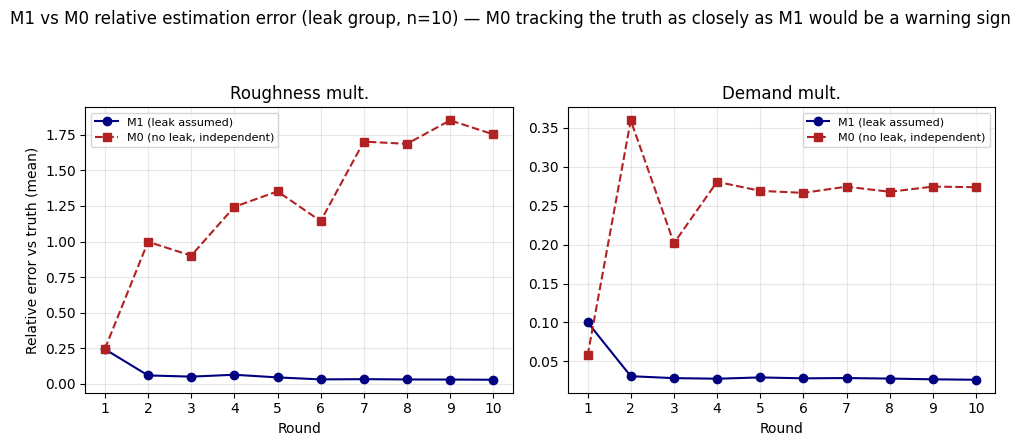

In [11]:
if leak_dfs and all('estimated_roughness_m0' in d.columns for d in leak_dfs.values()):
    err_rough_m0 = rel_err_matrix(leak_dfs, 'estimated_roughness_m0', ACTUAL['rough'])
    err_demand_m0 = rel_err_matrix(leak_dfs, 'estimated_demand_m0', ACTUAL['demand'])

    fig, axs = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True)
    for ax, err_m1, err_m0, name in zip(
            axs, [err_rough, err_demand], [err_rough_m0, err_demand_m0],
            ['Roughness mult.', 'Demand mult.']):
        m1 = np.nanmean(err_m1, axis=0); m0 = np.nanmean(err_m0, axis=0)
        ax.plot(rounds, m1, 'o-', color='navy', label='M1 (leak assumed)')
        ax.plot(rounds, m0, 's--', color='firebrick', label='M0 (no leak, independent)')
        ax.set_title(name)
        ax.set_xlabel('Round')
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.grid(alpha=0.3); ax.legend(fontsize=8)
    axs[0].set_ylabel('Relative error vs truth (mean)')
    plt.suptitle(f'M1 vs M0 relative estimation error (leak group, n={len(leak_dfs)}) — '
                 'M0 tracking the truth as closely as M1 would be a warning sign')
    plt.tight_layout(rect=[0, 0, 1, 0.92])
    plt.savefig('m0_vs_m1_relative_error.png', dpi=150, transparent=True)
    plt.show()
else:
    print('columns estimated_roughness_m0 / estimated_demand_m0 not found -- '
          'either pre-m0fix results or no finished samples yet')

## 8. Figure 6 — ESS (M1/M0) per round, collapse check

If `ess_m1` / `ess_m0` drop low (say below 10), the PMC has narrowed too aggressively. The v2c
collapse guard reduces this but does not eliminate it entirely, so it is worth checking. The
`is_clean` column can be used for a final filter.

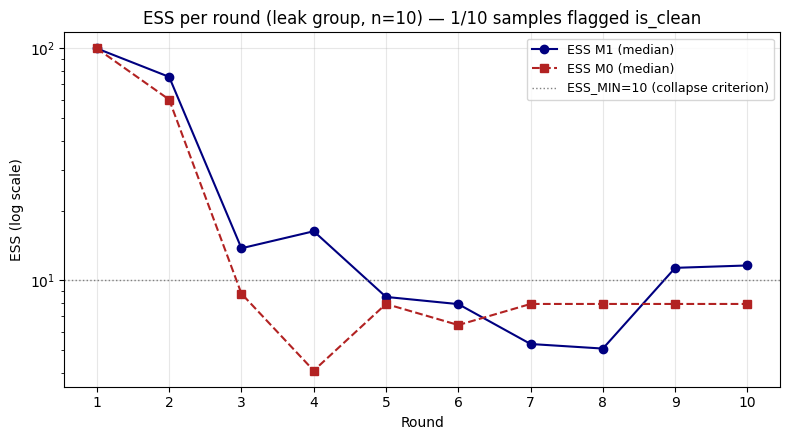

In [12]:
if leak_dfs and all('ess_m1' in d.columns for d in leak_dfs.values()):
    ess_m1_mat = to_matrix(leak_dfs, 'ess_m1')
    ess_m0_mat = to_matrix(leak_dfs, 'ess_m0')
    n_clean = sum(bool(d['is_clean'].iloc[0]) for d in leak_dfs.values() if 'is_clean' in d.columns)

    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(rounds, np.nanmedian(ess_m1_mat, axis=0), 'o-', color='navy', label='ESS M1 (median)')
    ax.plot(rounds, np.nanmedian(ess_m0_mat, axis=0), 's--', color='firebrick', label='ESS M0 (median)')
    ax.axhline(10, linestyle=':', color='0.5', linewidth=1, label='ESS_MIN=10 (collapse criterion)')
    ax.set_yscale('log')
    ax.set_xlabel('Round'); ax.set_ylabel('ESS (log scale)')
    ax.set_title(f'ESS per round (leak group, n={len(leak_dfs)}) — '
                 f'{n_clean}/{len(leak_dfs)} samples flagged is_clean')
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(alpha=0.3); ax.legend(fontsize=9)
    plt.tight_layout()
    plt.savefig('ess_per_round.png', dpi=150, transparent=True)
    plt.show()
else:
    print('columns ess_m1 / ess_m0 not found -- '
          'either pre-m0fix results or no finished samples yet')